# 20251218 Feronia salinity time course sc 291 ~ 294 DE GeneOverlap with hormone genes
This runs within the muscat Conda environment

In [1]:
# Check the conda env running, it's important that you're running in the correct conda env
# Don't change anything here
Sys.getenv("CONDA_DEFAULT_ENV")

[1] "muscat"

In [2]:
# Check Seurat version, it's important that you're using the correct version of Seurat
# scKB_copilot: Seurat 3; seu4_label_transfer: Seurat 4; muscat: Seurat 5
# Don't change anything here
packageVersion("Seurat")

[1] ‘5.2.1’

In [3]:
# Clean the environment and set the directory
# Change the directory to your project folder under your name
rm(list=ls())
# NOTE: lab cluster path below -- change it to your own path
setwd("/resnick/groups/NolanLab/cchen/Feronia/analysis")

In [4]:
# Load the libraries
# Don't change anything here
suppressMessages(library(tidyverse))
suppressMessages(library(Seurat))
suppressMessages(library(cowplot))
suppressMessages(library(future))
suppressMessages(library(grid))
suppressMessages(library(gridExtra))
suppressMessages(library(circlize))
suppressMessages(library(gprofiler2))
suppressMessages(library(ggrepel))
suppressMessages(library(ggplot2))
suppressMessages(library(data.table))
suppressMessages(library(muscat))
suppressMessages(library(purrr))
suppressMessages(library(GeneOverlap))
suppressMessages(library(ComplexHeatmap))
suppressMessages(library(limma))
suppressMessages(library(scran))
suppressMessages(library(ggplot2))

suppressMessages(library(proxy))
# suppressMessages(library(matlab))
suppressMessages(library(Matrix))


In [5]:
# Check the loaded packages and their versions. 
# # Be sure to execute this! It's important for reproducibility and debugging
# Don't change anything here
sessionInfo()

R version 4.3.3 (2024-02-29)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: Red Hat Enterprise Linux 9.5 (Plow)

Matrix products: default
BLAS/LAPACK: /resnick/groups/NolanLab/cchen/miniconda3/envs/muscat/lib/libopenblasp-r0.3.27.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=en_US.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8    
 [5] LC_MONETARY=en_US.UTF-8    LC_MESSAGES=en_US.UTF-8   
 [7] LC_PAPER=en_US.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

time zone: America/Los_Angeles
tzcode source: system (glibc)

attached base packages:
[1] stats4    grid      stats     graphics  grDevices utils     datasets 
[8] methods   base     

other attached packages:
 [1] Matrix_1.6-5                proxy_0.4-27               
 [3] scran_1.30.2                scuttle_1.12.0             
 [5] SingleCellExperiment_1.24.0 Summ

In [6]:
# future.globals.maxSize sets the maximum size (in bytes) for global variables in the future package during parallel processing.  
 options(future.globals.maxSize = 200 * 1024^3) 

In [7]:
# Read in the DE results
# NOTE: lab cluster path below -- change it to your own path
sig_DE_fil <- read.delim("/resnick/groups/NolanLab/cchen/Feronia/analysis/muscat_result/20260317_salinity_timecourse_useDateT_noSuspiciousClusters/group_timecelltypeannoLi/fer_4-WT/sig_de_fil.csv",
                        sep = ",", header = T)

head(sig_DE_fil)

,X,gene,cluster_id,sc_292.cpm,sc_294.cpm,sc_291.cpm,sc_293.cpm,sc_292.frq,sc_294.frq,sc_291.frq,⋯,p_val,p_adj.loc,p_adj.glb,contrast,gene.y,non,TF_Name,Description,up_dn_label,clust_up_dn
,<int>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,1,AT3G51550,Elongation_Cortex,0.165,0.362,288.0,323.0,0.00322,0.00164,0.830,⋯,4.05e-230,8.44e-226,2.91e-224,fer_4-WT,FER,Gene Expression,NA,NA,Down,Elongation_Cortex_Down
2,2,AT3G51550,Elongation_Phloem Pole Pericycle,0.000,0.267,173.0,169.0,0.00000,0.00305,0.711,⋯,7.28e-190,1.51e-185,2.62e-184,fer_4-WT,FER,Gene Expression,NA,NA,Down,Elongation_Phloem Pole Pericycle_Down
3,3,AT3G51550,Elongation_Trichoblast,0.000,1.690,228.0,297.0,0.00000,0.01380,0.916,⋯,6.68e-177,1.40e-172,1.60e-171,fer_4-WT,FER,Gene Expression,NA,NA,Down,Elongation_Trichoblast_Down
4,4,AT3G51550,Proliferation Domain_Trichoblast,0.000,0.669,80.2,71.9,0.00000,0.00439,0.604,⋯,7.70e-170,1.57e-165,1.38e-164,fer_4-WT,FER,Gene Expression,NA,NA,Down,Proliferation Domain_Trichoblast_Down
5,5,AT3G51550,Elongation_Endodermis,0.000,0.111,240.0,252.0,0.00000,0.00141,0.816,⋯,3.08e-151,6.51e-147,4.43e-146,fer_4-WT,FER,Gene Expression,NA,NA,Down,Elongation_Endodermis_Down
6,6,AT3G59370,Elongation_Phloem Pole Pericycle,1090.000,2160.000,5390.0,4820.0,0.76200,0.69800,0.903,⋯,2.70e-135,2.79e-131,3.23e-130,fer_4-WT,AT3G59370,Gene Expression,NA,NA,Down,Elongation_Phloem Pole Pericycle_Down


In [8]:
# Read in the background genes for doing the DE analysis
# NOTE: lab cluster path below -- change it to your own path
all_bg <- read.delim("/resnick/groups/NolanLab/cchen/Feronia/analysis/muscat_result/20260317_salinity_timecourse_useDateT_noSuspiciousClusters/group_timecelltypeannoLi/fer_4-WT/all_bg.csv",
                        sep = ",", header = T)

In [9]:
head(all_bg, 3)

,X,gene,cluster_id,sc_292.cpm,sc_294.cpm,sc_291.cpm,sc_293.cpm,sc_292.frq,sc_294.frq,sc_291.frq,sc_293.frq,fer_4.frq,WT.frq,logFC,logCPM,F,p_val,p_adj.loc,p_adj.glb,contrast
,<int>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,1,AT1G01050,Distal Columella,325.0,302.0,240.0,252,0.851,0.787,0.746,0.845,0.817,0.794,0.347,8.14,5.530,0.0187,0.272,0.315,fer_4-WT
2,2,AT1G01090,Distal Columella,36.9,36.3,37.9,27,0.255,0.204,0.222,0.201,0.228,0.212,0.188,5.15,0.981,0.3220,0.921,0.990,fer_4-WT
3,3,AT1G01100,Distal Columella,267.0,258.0,242.0,203,0.723,0.716,0.655,0.741,0.719,0.697,0.244,7.93,2.710,0.0995,0.627,0.732,fer_4-WT


In [10]:
# Parameters used in the muscat function for filtering DE
p_val_thres=0.05 
FC_thres=1.5
filter_freq=0.1 # freq to filter expression above

In [11]:
# Filter 
sig_DE_fil <- sig_DE_fil %>%
   filter(`p_adj.loc`<=p_val_thres & abs(`logFC`) > log2(FC_thres))

In [12]:
# Read in hormone genes
# NOTE: lab cluster path below -- change it to your own path
ABA <- read.csv("/resnick/groups/NolanLab/shared_resources/source_files/gene_lists/ABA.csv", header = T)
# NOTE: lab cluster path below -- change it to your own path
ACC <- read.csv("/resnick/groups/NolanLab/shared_resources/source_files/gene_lists/ACC.csv", header = T)
# NOTE: lab cluster path below -- change it to your own path
BR <- read.csv("/resnick/groups/NolanLab/shared_resources/source_files/gene_lists/BR.csv", header = T)
# NOTE: lab cluster path below -- change it to your own path
CK <- read.csv("/resnick/groups/NolanLab/shared_resources/source_files/gene_lists/CK.csv", header = T)
# NOTE: lab cluster path below -- change it to your own path
GA <- read.csv("/resnick/groups/NolanLab/shared_resources/source_files/gene_lists/GA.csv", header = T)
# NOTE: lab cluster path below -- change it to your own path
IAA <- read.csv("/resnick/groups/NolanLab/shared_resources/source_files/gene_lists/IAA.csv", header = T)
# NOTE: lab cluster path below -- change it to your own path
JA <- read.csv("/resnick/groups/NolanLab/shared_resources/source_files/gene_lists/Hickman_2017_JA.csv", header = T)
# NOTE: lab cluster path below -- change it to your own path
SA <- read.csv("/resnick/groups/NolanLab/shared_resources/source_files/gene_lists/SA.csv", header = T)

In [13]:
head(SA, 3)

,GeneID
,<chr>
1,AT1G29460
2,AT4G18970
3,AT1G36160


In [14]:
# Bind the hormone dfs into one
hormone_genes <- bind_rows(
  ABA %>% transmute(GeneID, Hormone = "ABA"),
  ACC %>% transmute(GeneID, Hormone = "ACC"),
  BR  %>% transmute(GeneID, Hormone = "BR"),
  CK  %>% transmute(GeneID, Hormone = "CK"),
  GA  %>% transmute(GeneID, Hormone = "GA"),
  IAA %>% transmute(GeneID, Hormone = "IAA"),
  JA  %>% transmute(GeneID, Hormone = "JA"),
  SA  %>% transmute(GeneID, Hormone = "SA")
)

head(hormone_genes, 3)

,GeneID,Hormone
,<chr>,<chr>
1,AT1G01120,ABA
2,AT1G01140,ABA
3,AT1G01225,ABA


In [15]:
# The background gene size
genome_size <- length(unique(all_bg$gene))
genome_size

[1] 17554

In [16]:
# Create DE genes list (format for Gene Overlap input)
markers_sel <- select(sig_DE_fil, gene, cluster_id)

markers_list <- split(markers_sel, f=markers_sel$cluster_id)


In [17]:
length(markers_list)
class(markers_list)

[1] 34

[1] "list"

In [18]:
sort(lengths(markers_list))

Distal Columella 
                                               2 
                         Distal Lateral Root Cap 
                                               2 
                         Elongation_Atrichoblast 
                                               2 
                               Elongation_Cortex 
                                               2 
                           Elongation_Endodermis 
                                               2 
          Elongation_Metaphloem & Companion Cell 
                                               2 
                            Elongation_Metaxylem 
                                               2 
                Elongation_Phloem Pole Pericycle 
                                               2 
                           Elongation_Procambium 
                                               2 
                           Elongation_Protoxylem 
                                               2 
                          Elongation_Trichoblast 
                                               2 
                 Elongation_Xylem Pole Pericycle 
                                               2 
                         Maturation_Atrichoblast 
                                               2 
                               Maturation_Cortex 
                                               2 
                           Maturation_Endodermis 
                                               2 
                           Maturation_Procambium 
                                               2 
                           Maturation_Protoxylem 
                                               2 
                          Maturation_Trichoblast 
                                               2 
                 Maturation_Xylem Pole Pericycle 
                                               2 
               Proliferation Domain_Atrichoblast 
                                               2 
                     Proliferation Domain_Cortex 
                                               2 
                 Proliferation Domain_Endodermis 
                                               2 
Proliferation Domain_Metaphloem & Companion Cell 
                                               2 
                Proliferation Domain_Trichoblast 
                                               2 
       Proliferation Domain_Xylem Pole Pericycle 
                                               2 
                       Proximal Lateral Root Cap 
                                               2 
                  Transition Domain_Atrichoblast 
                                               2 
                        Transition Domain_Cortex 
                                               2 
                    Transition Domain_Endodermis 
                                               2 
   Transition Domain_Metaphloem & Companion Cell 
                                               2 
                    Transition Domain_Procambium 
                                               2 
                    Transition Domain_Protoxylem 
                                               2 
                   Transition Domain_Trichoblast 
                                               2 
          Transition Domain_Xylem Pole Pericycle 
                                               2

In [19]:
#this makes list from long df of gene lists - TARGET is what we want to keep
markers_list  <- lapply(markers_list, function(x) x[names(x)=="gene"])


In [20]:
# convert each sublist into character and eliminate duplicates
markers_list  <- lapply(markers_list, function(x) as.character(unique(x$gene)))

In [21]:
markers_list

$`Distal Columella`
  [1] "AT3G51550" "AT3G51520" "AT1G65570" "AT4G26260" "AT1G75750" "AT5G46890"
  [7] "AT4G17340" "AT1G13930" "AT5G47450" "AT4G22460" "AT1G13420" "AT5G35940"
 [13] "AT1G65690" "AT5G46900" "AT3G26520" "AT3G55970" "AT4G01360" "AT2G37040"
 [19] "AT1G22530" "AT5G24580" "AT2G43150" "AT3G53420" "AT3G61430" "AT2G36830"
 [25] "AT4G35100" "AT5G38710" "AT2G30930" "AT2G37170" "AT3G51500" "AT3G16240"
 [31] "AT5G23840" "AT2G47550" "AT1G21120" "AT1G72150" "AT5G44585" "AT5G23750"
 [37] "AT3G01190" "AT5G40450" "AT3G44310" "AT1G01620" "AT5G53250" "AT5G64100"
 [43] "AT3G23090" "AT3G30720" "AT5G43570" "AT4G29905" "AT5G42380" "AT4G20260"
 [49] "AT1G52200" "AT2G38240" "AT4G22666" "AT4G15910" "AT1G77760" "AT2G22750"
 [55] "AT3G19450" "AT1G15385" "AT5G14330" "AT2G45180" "AT5G13930" "AT4G00430"
 [61] "AT5G08640" "AT1G21310" "AT5G10430" "AT5G38700" "AT3G53260" "AT3G05500"
 [67] "AT1G02930" "AT4G12545" "AT4G15550" "AT4G12510" "AT1G78100" "AT4G30170"
 [73] "AT2G18980" "AT3G50640" "AT1G03870" "AT3G51240" "AT2G45960" "AT4G27410"
 [79] "AT4G15760" "AT3G01513" "AT1G54010" "AT3G05900" "AT4G23100" "AT3G15356"
 [85] "AT4G16260" "AT4G26010" "AT1G27140" "AT1G02920" "AT1G18193" "AT1G02900"
 [91] "AT5G66280" "AT3G59765" "AT1G52760" "AT5G64870" "AT4G35060" "AT2G36100"
 [97] "AT5G44020" "AT4G12550" "AT2G29750" "AT1G23720" "AT1G76250" "AT2G27130"
[103] "AT5G03210" "AT1G05100" "AT3G28550" "AT2G15970" "AT1G12090" "AT2G29980"
[109] "AT2G41730" "AT5G24660" "AT4G15160" "AT1G44318" "AT5G15150" "AT5G65390"
[115] "AT2G18230" "AT3G16450" "AT3G23530" "AT2G35770" "AT5G13080" "AT1G72160"
[121] "AT5G20270" "AT3G59370" "AT2G34080" "AT1G80440" "AT5G06300" "AT4G23400"
[127] "AT5G43350" "AT4G10350" "AT1G06330" "AT5G51520" "AT3G28210" "AT2G44790"
[133] "AT1G17890" "AT5G56540" "AT1G20070" "AT5G12340" "AT5G44380" "AT3G15540"
[139] "AT5G15490" "AT1G12080" "AT5G06570" "AT1G05340" "AT3G14660" "AT5G23220"
[145] "AT2G23930" "AT2G40340" "AT3G09940" "AT3G47960" "AT4G12520" "AT1G28470"
[151] "AT2G27690" "AT3G28910" "AT1G53830" "AT4G12840" "AT1G62975" "AT1G73260"
[157] "AT3G16440" "AT5G64750" "AT3G04720" "AT2G32020" "AT5G01750" "AT4G38140"
[163] "AT4G15300" "AT5G21940" "AT5G40730" "AT3G61640" "AT2G34070" "AT1G59960"
[169] "AT3G45230" "AT2G43820" "AT3G57020" "AT1G10200" "AT3G04730" "AT1G49500"
[175] "AT3G49780" "AT4G30670" "AT5G54160" "AT2G20750" "AT1G77840" "AT5G63600"
[181] "AT1G14960" "AT2G30860" "AT1G07290" "AT5G43620" "AT3G49845" "AT5G57625"
[187] "AT3G53750" "AT5G05880" "AT1G27400" "AT5G66580" "AT2G01880" "AT5G51440"
[193] "AT3G29250" "AT2G32210" "AT3G47380" "AT1G69930" "AT5G65830" "AT2G25980"
[199] "AT1G35140" "AT4G37790" "AT3G03780" "AT1G75780" "AT1G69920" "AT4G27870"
[205] "AT1G43670" "AT5G10130" "AT2G29500" "AT3G22600" "AT3G13435" "AT1G33280"
[211] "AT5G24165" "AT3G59440" "AT5G15265" "AT1G62980" "AT5G62770" "AT5G17820"
[217] "AT5G15160" "AT1G29025" "AT1G05680" "AT5G21280" "AT5G67390" "AT1G55210"
[223] "AT2G23630" "AT5G17460" "AT5G25890" "AT4G33467" "AT5G52310" "AT5G55110"
[229] "AT5G60530" "AT1G66500" "AT5G03510" "AT1G66400" "AT5G63650" "AT3G08590"
[235] "AT1G02810" "AT1G75000" "AT1G33800" "AT4G19230" "AT5G18150" "AT3G15710"
[241] "AT1G65960" "AT2G31200" "AT3G54580" "AT4G13395" "AT5G07010" "AT1G53700"
[247] "AT1G65310" "AT1G53680" "AT3G56710" "AT1G07985" "AT5G17520" "AT2G32960"
[253] "AT1G04040" "AT3G54770" "AT4G16760" "AT5G60660" "AT2G36780" "AT5G19230"
[259] "AT2G25810" "AT5G62180" "AT2G32930" "AT1G12110" "AT3G59900" "AT5G45775"
[265] "AT1G23040" "AT5G04970" "AT5G22250" "AT5G44610" "AT2G15910" "AT4G01630"
[271] "AT5G19340" "AT4G11210" "AT2G40470" "AT1G25560" "AT1G10530" "AT4G37850"
[277] "AT3G21680" "AT3G47836" "AT1G51420" "AT4G03420" "AT1G71380" "AT1G30690"
[283] "AT4G39780" "AT1G07150" "AT4G13660" "AT1G15380" "AT4G29930" "AT5G67480"
[289] "AT5G62530" "AT3G02840" "AT4G01070" "AT5G50450" "AT1G50720" "AT1G07400"
[295] "AT2G14878" "AT4G39660" "AT1G07750" "AT1G20140" "AT5G60800" "AT5G14970"
[301] "AT3G54590" "AT3G22880" "AT2G48150" "AT2G17500" "AT4G25720" "AT3G11530"
[3

In [22]:
length(markers_list)

[1] 34

In [23]:
# Create Hormone Gene list (format for Gene Overlap input)
hormone_list <- split(hormone_genes, f=hormone_genes$Hormone)
hormone_list  <- lapply(hormone_list, function(x) x[names(x)=="GeneID"])
hormone_list  <- lapply(hormone_list, function(x) as.character(unique(x$GeneID)))

length(hormone_list)

[1] 8

In [24]:
hormone_list

$ABA
   [1] "AT1G01120" "AT1G01140" "AT1G01225" "AT1G01240" "AT1G01360" "AT1G01470"
   [7] "AT1G01520" "AT1G01600" "AT1G01610" "AT1G01650" "AT1G01720" "AT1G02200"
  [13] "AT1G02205" "AT1G02310" "AT1G02400" "AT1G02470" "AT1G02660" "AT1G02700"
  [19] "AT1G02816" "AT1G02850" "AT1G03080" "AT1G03290" "AT1G03520" "AT1G03610"
  [25] "AT1G03700" "AT1G03790" "AT1G04020" "AT1G04220" "AT1G04310" "AT1G04360"
  [31] "AT1G04560" "AT1G04830" "AT1G04990" "AT1G05100" "AT1G05450" "AT1G05560"
  [37] "AT1G05680" "AT1G06050" "AT1G06430" "AT1G06570" "AT1G06780" "AT1G07040"
  [43] "AT1G07080" "AT1G07250" "AT1G07430" "AT1G07470" "AT1G07720" "AT1G07870"
  [49] "AT1G08040" "AT1G08190" "AT1G08230" "AT1G08250" "AT1G08320" "AT1G08500"
  [55] "AT1G08570" "AT1G08900" "AT1G08920" "AT1G08970" "AT1G09350" "AT1G09480"
  [61] "AT1G09520" "AT1G09530" "AT1G09870" "AT1G09920" "AT1G09960" "AT1G10070"
  [67] "AT1G10080" "AT1G10090" "AT1G10150" "AT1G10370" "AT1G10380" "AT1G10410"
  [73] "AT1G10480" "AT1G10585" "AT1G10740" "AT1G11190" "AT1G11210" "AT1G11600"
  [79] "AT1G11790" "AT1G12580" "AT1G12640" "AT1G12845" "AT1G12990" "AT1G13090"
  [85] "AT1G13195" "AT1G13580" "AT1G13740" "AT1G13930" "AT1G13990" "AT1G14530"
  [91] "AT1G14730" "AT1G15260" "AT1G15340" "AT1G15430" "AT1G15740" "AT1G15960"
  [97] "AT1G16060" "AT1G16510" "AT1G16520" "AT1G16840" "AT1G16850" "AT1G16860"
 [103] "AT1G17020" "AT1G17050" "AT1G17120" "AT1G17230" "AT1G17550" "AT1G17840"
 [109] "AT1G17870" "AT1G17950" "AT1G18100" "AT1G18460" "AT1G18710" "AT1G18810"
 [115] "AT1G18870" "AT1G19180" "AT1G19200" "AT1G19230" "AT1G19650" "AT1G19860"
 [121] "AT1G19970" "AT1G20070" "AT1G20440" "AT1G20450" "AT1G20590" "AT1G21000"
 [127] "AT1G21010" "AT1G21130" "AT1G21170" "AT1G21400" "AT1G21410" "AT1G21460"
 [133] "AT1G21590" "AT1G21670" "AT1G21780" "AT1G21790" "AT1G21980" "AT1G22160"
 [139] "AT1G22190" "AT1G22370" "AT1G22640" "AT1G22930" "AT1G23040" "AT1G23120"
 [145] "AT1G23190" "AT1G23260" "AT1G23330" "AT1G23430" "AT1G23710" "AT1G23800"
 [151] "AT1G24440" "AT1G24600" "AT1G25450" "AT1G25520" "AT1G25530" "AT1G25560"
 [157] "AT1G26670" "AT1G26690" "AT1G27200" "AT1G27300" "AT1G27320" "AT1G27470"
 [163] "AT1G27730" "AT1G27760" "AT1G27950" "AT1G28200" "AT1G28260" "AT1G28370"
 [169] "AT1G28960" "AT1G29240" "AT1G29330" "AT1G29395" "AT1G29400" "AT1G29670"
 [175] "AT1G29760" "AT1G30120" "AT1G30300" "AT1G30360" "AT1G30500" "AT1G30620"
 [181] "AT1G30640" "AT1G30700" "AT1G31470" "AT1G31480" "AT1G31750" "AT1G31820"
 [187] "AT1G31830" "AT1G32400" "AT1G32410" "AT1G32440" "AT1G32640" "AT1G33800"
 [193] "AT1G34260" "AT1G34630" "AT1G34670" "AT1G35180" "AT1G36160" "AT1G36380"
 [199] "AT1G42990" "AT1G43160" "AT1G44760" "AT1G44770" "AT1G44800" "AT1G47128"
 [205] "AT1G47270" "AT1G47610" "AT1G47960" "AT1G48100" "AT1G48320" "AT1G48840"
 [211] "AT1G49430" "AT1G49450" "AT1G49670" "AT1G50020" "AT1G50290" "AT1G50630"
 [217] "AT1G50640" "AT1G50940" "AT1G51140" "AT1G51500" "AT1G51700" "AT1G52540"
 [223] "AT1G52560" "AT1G52680" "AT1G52690" "AT1G52880" "AT1G52890" "AT1G53090"
 [229] "AT1G53170" "AT1G53270" "AT1G53560" "AT1G53570" "AT1G53580" "AT1G53885"
 [235] "AT1G54100" "AT1G54120" "AT1G54130" "AT1G54160" "AT1G54270" "AT1G54290"
 [241] "AT1G54540" "AT1G54570" "AT1G54710" "AT1G54740" "AT1G54830" "AT1G55110"
 [247] "AT1G55265" "AT1G55510" "AT1G55545" "AT1G55730" "AT1G55760" "AT1G56170"
 [253] "AT1G56320" "AT1G56580" "AT1G56600" "AT1G58032" "AT1G58170" "AT1G58180"
 [259] "AT1G58270" "AT1G58340" "AT1G58360" "AT1G59650" "AT1G59700" "AT1G59740"
 [265] "AT1G60190" "AT1G60430" "AT1G60440" "AT1G60590" "AT1G61670" "AT1G61890"
 [271] "AT1G62045" "AT1G62300" "AT1G62510" "AT1G62540" "AT1G62570" "AT1G62610"
 [277] "AT1G62660" "AT1G62710" "AT1G62810" "AT1G62820" "AT1G63010" "AT1G63420"
 [283] "AT1G63720" "AT1G63840" "AT1G64060" "AT1G64110" "AT1G64380" "AT1G64470"
 [289] "AT1G64660" "AT1G64810" "AT1G64890" "AT1G64950" "AT1G64970" "AT1G65520"
 [295] "AT1G65690" "AT1G66350" "AT1G66760" "AT1G66890" "AT1G67060" "AT1G67300"
 [301] "AT1G67310" "AT1G67360" "AT1G67730" "A

In [25]:
sort(lengths(hormone_list))

GA   CK  ACC  IAA   SA  ABA   JA   BR 
 122  495  532  785 1051 2914 3611 4987

In [26]:
# Gene Overlap test
gom.obj <- newGOM(markers_list, hormone_list, genome.size=genome_size)

In [27]:
class(gom.obj)

[1] "GeneOverlapMatrix"
attr(,"package")
[1] "GeneOverlap"

In [28]:
int <- getNestedList(gom.obj, "intersection")
int_matrix <- getMatrix(gom.obj, "intersection")
p.val <- getMatrix(gom.obj, "pval")
JC <- getMatrix(gom.obj, "Jaccard")

# log of p.val for intersection
p.val_log <- -log10(p.val + 1e-200)

In [29]:
# p-value cutoff for showing colors
cutoff <- -log10(0.05)  # ≈ 1.301

# Adjust the legend color using the cutoff and the max limit value
col_fun <- colorRamp2(
  c(0, cutoff, 10),
  c("white", "beige", "red")
)

# Heatmap
olap <- Heatmap(
  p.val_log,
  name = "-log10_pval",
  col = col_fun,
  column_title = "Number of hormonal genes among DEGs in each cell type",
  cluster_rows = TRUE,
  cluster_columns = TRUE,
  use_raster = FALSE,
  show_column_names = TRUE,
  show_row_names = TRUE,
  show_row_dend = FALSE,
  show_column_dend = FALSE,
  column_names_rot = 0,
  column_names_centered = TRUE,
  rect_gp = gpar(col = "lightgrey", lwd = 0.5),
  cell_fun = function(j, i, x, y, width, height, fill) {
    grid.text(sprintf("%.0f", int_matrix[i, j]), x, y,
              gp = gpar(fontsize = 10))
  }
)


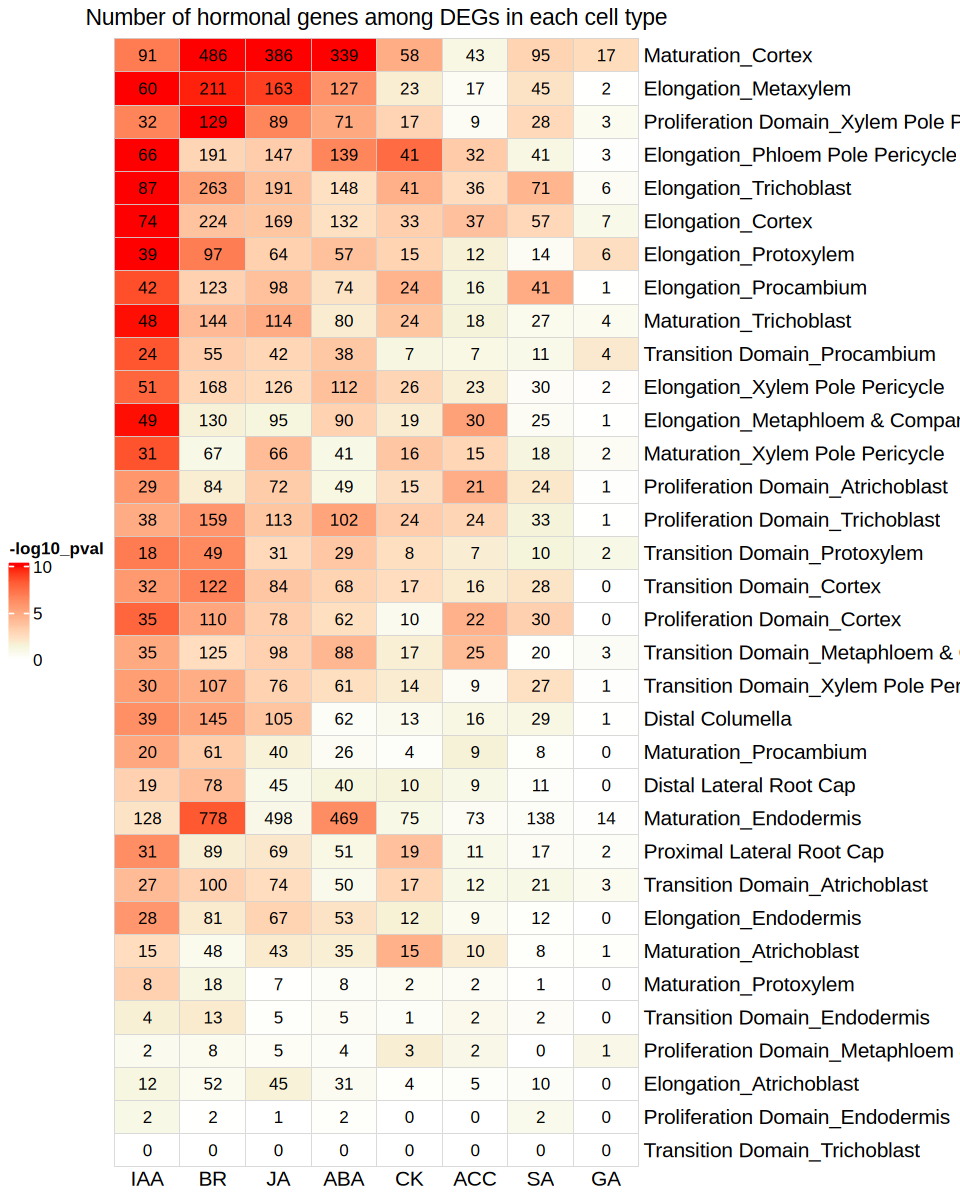

In [30]:
# Plot heatmap
options(repr.plot.width = 8, repr.plot.height = 10)

draw(
  olap,
  heatmap_legend_side = "left",
  padding = unit(c(2, 2, 2, 6), "mm")  # top, right, bottom, left
)

In [31]:
# Save the plot
# padding - bottom, left, top, right
#pdf(file=paste("20260317_feronia_salinity_DE_hormone_overlap_newIntegratedSeurat3_NoSuspicousCluster.pdf",sep=""), width=9, height=10)
draw(
  olap,
  heatmap_legend_side = "left",
  padding = unit(c(2, 2, 2, 45), "mm")  # top, right, bottom, left
)
#dev.off()

pdf 
  2